# Few-Shot Learning for Bird Species Classification — Results (10 Base / 10 Novel)

**Thesis:** Evaluation of Few-Shot Learning Paradigms for Bird Species Classification
**Dataset:** 20 bird species split into **10 base** and **10 novel** classes. ResNet-50 backbone.
**Evaluation:** 5-way K-shot episodic protocol on novel classes (600 episodes), K ∈ {1, 3, 5}.

---
**Novel classes (10):** ALBERTS TOWHEE, ALEXANDRINE PARAKEET, ALPINE CHOUGH, ALTAMIRA YELLOWTHROAT,
AMERICAN AVOCET, AMERICAN BITTERN, AMERICAN COOT, AMERICAN FLAMINGO, AMERICAN GOLDFINCH, AMERICAN KESTREL

Each evaluation episode randomly samples 5 of the 10 novel classes (5-way K-shot).


In [1]:
%matplotlib inline
import os, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.ion()
plt.rcParams["figure.dpi"]  = 120
plt.rcParams["savefig.dpi"] = 150

NB_DIR = os.getcwd()
ROOT   = os.path.normpath(os.path.join(NB_DIR, '..'))
RES    = os.path.join(ROOT, 'results')
ANALYSIS = os.path.join(RES, 'analysis')
os.makedirs(ANALYSIS, exist_ok=True)

print(f"ROOT : {ROOT}")
print(f"RES  : {RES}")
print(f"matplotlib backend: {matplotlib.get_backend()}")

PATHS = {
    # ── Supervised Baselines (base10) ──────────────────────────────────────────
    'base10_json'          : f'{RES}/baseline/resnet50/base10/base_test/summary.json',
    'kshot5_b10_json'      : f'{RES}/baseline/resnet50/base10/novel_kshot_5/summary.json',
    # ── NCC (base10 backbone) ─────────────────────────────────────────────────
    'ncc_1shot_euc_json'   : f'{RES}/baseline/resnet50/base10/novel_ncc/1shot_euclidean/summary.json',
    'ncc_1shot_man_json'   : f'{RES}/baseline/resnet50/base10/novel_ncc/1shot_manhattan/summary.json',
    'ncc_3shot_euc_json'   : f'{RES}/baseline/resnet50/base10/novel_ncc/3shot_euclidean/summary.json',
    'ncc_3shot_man_json'   : f'{RES}/baseline/resnet50/base10/novel_ncc/3shot_manhattan/summary.json',
    'ncc_5shot_euc_json'   : f'{RES}/baseline/resnet50/base10/novel_ncc/5shot_euclidean/summary.json',
    'ncc_5shot_man_json'   : f'{RES}/baseline/resnet50/base10/novel_ncc/5shot_manhattan/summary.json',
    # ── ProtoNet ──────────────────────────────────────────────────────────────
    'proto_1shot_euc_json' : f'{RES}/proto_net/base10_novel10/1shot_euclidean/summary.json',
    'proto_1shot_man_json' : f'{RES}/proto_net/base10_novel10/1shot_manhattan/summary.json',
    'proto_3shot_euc_json' : f'{RES}/proto_net/base10_novel10/3shot_euclidean/summary.json',
    'proto_3shot_man_json' : f'{RES}/proto_net/base10_novel10/3shot_manhattan/summary.json',
    'proto_5shot_euc_json' : f'{RES}/proto_net/base10_novel10/5shot_euclidean/summary.json',
    'proto_5shot_man_json' : f'{RES}/proto_net/base10_novel10/5shot_manhattan/summary.json',
    # ── MatchingNet ───────────────────────────────────────────────────────────
    'match_1shot_json'     : f'{RES}/matching_net/base10_novel10/1shot/summary.json',
    'match_3shot_json'     : f'{RES}/matching_net/base10_novel10/3shot/summary.json',
    'match_5shot_json'     : f'{RES}/matching_net/base10_novel10/5shot/summary.json',
    # ── RelationNet ───────────────────────────────────────────────────────────
    'rel_1shot_json'       : f'{RES}/relation_net/base10_novel10/1shot/summary.json',
    'rel_3shot_json'       : f'{RES}/relation_net/base10_novel10/3shot/summary.json',
    'rel_5shot_json'       : f'{RES}/relation_net/base10_novel10/5shot/summary.json',
}

R = {}
for key, path in PATHS.items():
    if os.path.exists(path):
        with open(path) as f:
            R[key] = json.load(f)
    else:
        R[key] = None
        print(f"  [missing] {key}: {path}")

present = sum(1 for v in R.values() if v is not None)
print(f"\nLoaded {present}/{len(R)} result files.")

def acc(key):  return float(R[key]['mean_accuracy_pct']) if R[key] else float('nan')
def ci(key):   return float(R[key]['ci95_pct'])          if R[key] else 0.0

ROOT : .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity
RES  : .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results
matplotlib backend: inline

Loaded 20/20 result files.


---
## 1. Class Split Overview

**10 base classes** used for episodic training. **10 novel classes** for evaluation.
Each evaluation episode samples **5 of the 10** novel classes (5-way protocol).


In [2]:
BASE_CLASSES = [
    'ABBOTTS BABBLER', 'ABBOTTS BOOBY', 'ABYSSINIAN GROUND HORNBILL',
    'AFRICAN CROWNED CRANE', 'AFRICAN EMERALD CUCKOO', 'AFRICAN FIREFINCH',
    'AFRICAN OYSTER CATCHER', 'AFRICAN PIED HORNBILL', 'AFRICAN PYGMY GOOSE', 'ALBATROSS',
]
NOVEL_CLASSES = [
    'ALBERTS TOWHEE', 'ALEXANDRINE PARAKEET', 'ALPINE CHOUGH', 'ALTAMIRA YELLOWTHROAT',
    'AMERICAN AVOCET', 'AMERICAN BITTERN', 'AMERICAN COOT', 'AMERICAN FLAMINGO',
    'AMERICAN GOLDFINCH', 'AMERICAN KESTREL',
]

print(f'Base classes  ({len(BASE_CLASSES)}): {BASE_CLASSES}')
print(f'Novel classes ({len(NOVEL_CLASSES)}): {NOVEL_CLASSES}')
print('\nEpisodic eval: 5-way (5 of 10 novel sampled per episode), K-shot ∈ {1, 3, 5}')

Base classes  (10): ['ABBOTTS BABBLER', 'ABBOTTS BOOBY', 'ABYSSINIAN GROUND HORNBILL', 'AFRICAN CROWNED CRANE', 'AFRICAN EMERALD CUCKOO', 'AFRICAN FIREFINCH', 'AFRICAN OYSTER CATCHER', 'AFRICAN PIED HORNBILL', 'AFRICAN PYGMY GOOSE', 'ALBATROSS']
Novel classes (10): ['ALBERTS TOWHEE', 'ALEXANDRINE PARAKEET', 'ALPINE CHOUGH', 'ALTAMIRA YELLOWTHROAT', 'AMERICAN AVOCET', 'AMERICAN BITTERN', 'AMERICAN COOT', 'AMERICAN FLAMINGO', 'AMERICAN GOLDFINCH', 'AMERICAN KESTREL']

Episodic eval: 5-way (5 of 10 novel sampled per episode), K-shot ∈ {1, 3, 5}


---
## 2. NCC Baseline (base10 backbone)

Frozen ResNet-50 trained on 10 base classes. Nearest-centroid classification on novel embeddings.


In [3]:
SHOTS = [1, 3, 5]
print('NCC Baseline — base10 backbone')
print(f"{'Shot':>6} {'Euclidean':>12} {'CI95':>10}  {'Manhattan':>12} {'CI95':>10}")
print('-' * 60)
for s in SHOTS:
    e = R[f'ncc_{s}shot_euc_json']
    m = R[f'ncc_{s}shot_man_json']
    e_acc = f"{float(e['mean_accuracy_pct']):.2f}%" if e else '—'
    e_ci  = f"±{float(e['ci95_pct']):.2f}"           if e else '—'
    m_acc = f"{float(m['mean_accuracy_pct']):.2f}%" if m else '—'
    m_ci  = f"±{float(m['ci95_pct']):.2f}"           if m else '—'
    print(f"  {s}-shot  {e_acc:>12} {e_ci:>10}  {m_acc:>12} {m_ci:>10}")

NCC Baseline — base10 backbone
  Shot    Euclidean       CI95     Manhattan       CI95
------------------------------------------------------------
  1-shot        87.01%      ±0.81        76.28%      ±0.99
  3-shot        96.20%      ±0.41        90.25%      ±0.61
  5-shot        97.40%      ±0.33        92.90%      ±0.52


---
## 3. ProtoNet — base10/novel10


In [4]:
print('ProtoNet — base10/novel10')
print(f"{'Shot':>6} {'Euclidean':>12} {'CI95':>10}  {'Manhattan':>12} {'CI95':>10}")
print('-' * 60)
for s in SHOTS:
    e = R[f'proto_{s}shot_euc_json']
    m = R[f'proto_{s}shot_man_json']
    e_acc = f"{float(e['mean_accuracy_pct']):.2f}%" if e else '—'
    e_ci  = f"±{float(e['ci95_pct']):.2f}"           if e else '—'
    m_acc = f"{float(m['mean_accuracy_pct']):.2f}%" if m else '—'
    m_ci  = f"±{float(m['ci95_pct']):.2f}"           if m else '—'
    print(f"  {s}-shot  {e_acc:>12} {e_ci:>10}  {m_acc:>12} {m_ci:>10}")

ProtoNet — base10/novel10
  Shot    Euclidean       CI95     Manhattan       CI95
------------------------------------------------------------
  1-shot        88.45%      ±0.80        76.10%      ±1.00
  3-shot        94.83%      ±0.49        87.64%      ±0.73
  5-shot        95.77%      ±0.41        90.14%      ±0.64


---
## 4. MatchingNet — base10/novel10


In [5]:
print('MatchingNet — base10/novel10')
print(f"{'Shot':>6} {'Cosine':>12} {'CI95':>10}")
print('-' * 35)
for s in SHOTS:
    d = R[f'match_{s}shot_json']
    d_acc = f"{float(d['mean_accuracy_pct']):.2f}%" if d else '—'
    d_ci  = f"±{float(d['ci95_pct']):.2f}"           if d else '—'
    print(f"  {s}-shot  {d_acc:>12} {d_ci:>10}")

MatchingNet — base10/novel10
  Shot       Cosine       CI95
-----------------------------------
  1-shot        59.11%      ±1.01
  3-shot        63.35%      ±0.95
  5-shot        66.74%      ±0.94


---
## 5. RelationNet — base10/novel10


In [6]:
print('RelationNet — base10/novel10')
print(f"{'Shot':>6} {'Learned':>12} {'CI95':>10}")
print('-' * 35)
for s in SHOTS:
    d = R[f'rel_{s}shot_json']
    d_acc = f"{float(d['mean_accuracy_pct']):.2f}%" if d else '—'
    d_ci  = f"±{float(d['ci95_pct']):.2f}"           if d else '—'
    print(f"  {s}-shot  {d_acc:>12} {d_ci:>10}")

RelationNet — base10/novel10
  Shot      Learned       CI95
-----------------------------------
  1-shot        66.94%      ±1.18
  3-shot        74.89%      ±0.95
  5-shot        76.44%      ±0.84


---
## 6. K-Shot Trend — All Methods (b10/n10)


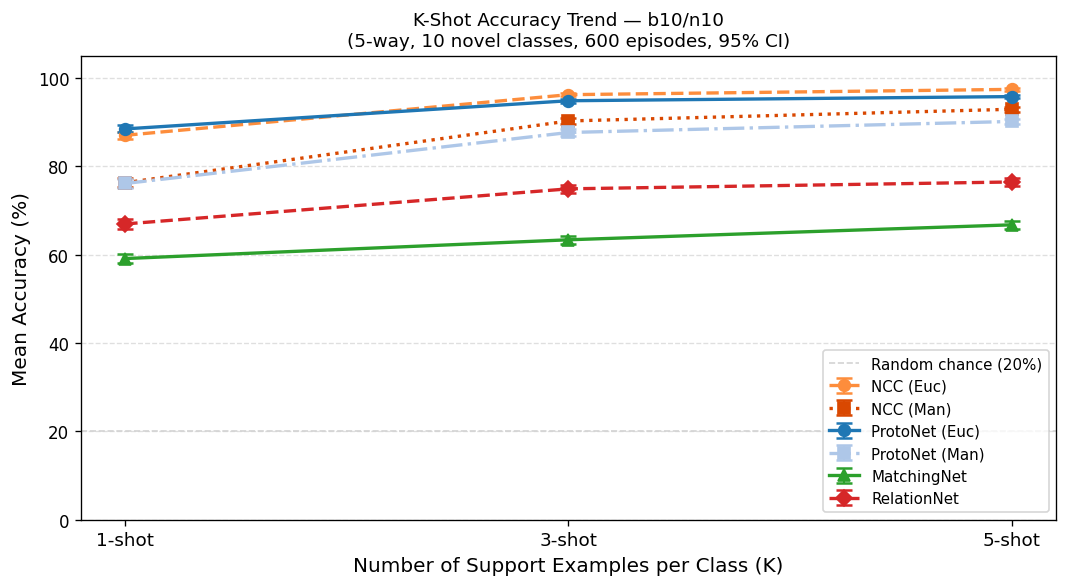

In [7]:
SHOTS = [1, 3, 5]
C = {'ncc_euc': '#fd8d3c', 'ncc_man': '#d94801',
     'proto_euc': '#1f77b4', 'proto_man': '#aec7e8',
     'match': '#2ca02c', 'rel': '#d62728'}

model_configs = [
    ('NCC (Euc)',      'ncc_{s}shot_euc_json',   C['ncc_euc'],   'o', '--'),
    ('NCC (Man)',      'ncc_{s}shot_man_json',   C['ncc_man'],   's', ':'),
    ('ProtoNet (Euc)', 'proto_{s}shot_euc_json', C['proto_euc'], 'o', '-'),
    ('ProtoNet (Man)', 'proto_{s}shot_man_json', C['proto_man'], 's', '-.'),
    ('MatchingNet',    'match_{s}shot_json',     C['match'],     '^', '-'),
    ('RelationNet',    'rel_{s}shot_json',       C['rel'],       'D', '--'),
]

fig, ax = plt.subplots(figsize=(9, 5))

for label, key_tmpl, color, marker, ls in model_configs:
    xs, ys, errs = [], [], []
    for s in SHOTS:
        key = key_tmpl.format(s=s)
        if R[key] is not None:
            xs.append(s)
            ys.append(float(R[key]['mean_accuracy_pct']))
            errs.append(float(R[key]['ci95_pct']))
    if xs:
        ax.errorbar(xs, ys, yerr=errs, label=label, color=color,
                    marker=marker, linestyle=ls, linewidth=2, markersize=7,
                    capsize=5, capthick=1.5, elinewidth=1.2)

ax.axhline(y=20, color='lightgray', linestyle='--', linewidth=1, label='Random chance (20%)')
ax.set_xticks(SHOTS)
ax.set_xticklabels([f'{k}-shot' for k in SHOTS], fontsize=11)
ax.set_xlabel('Number of Support Examples per Class (K)', fontsize=12)
ax.set_ylabel('Mean Accuracy (%)', fontsize=12)
ax.set_ylim(0, 105)
ax.set_title('K-Shot Accuracy Trend — b10/n10\n(5-way, 10 novel classes, 600 episodes, 95% CI)', fontsize=11)
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/b10n10_kshot_trend.png', dpi=150)
plt.show()

---
## 7. Accuracy Comparison Bar Chart (b10/n10)


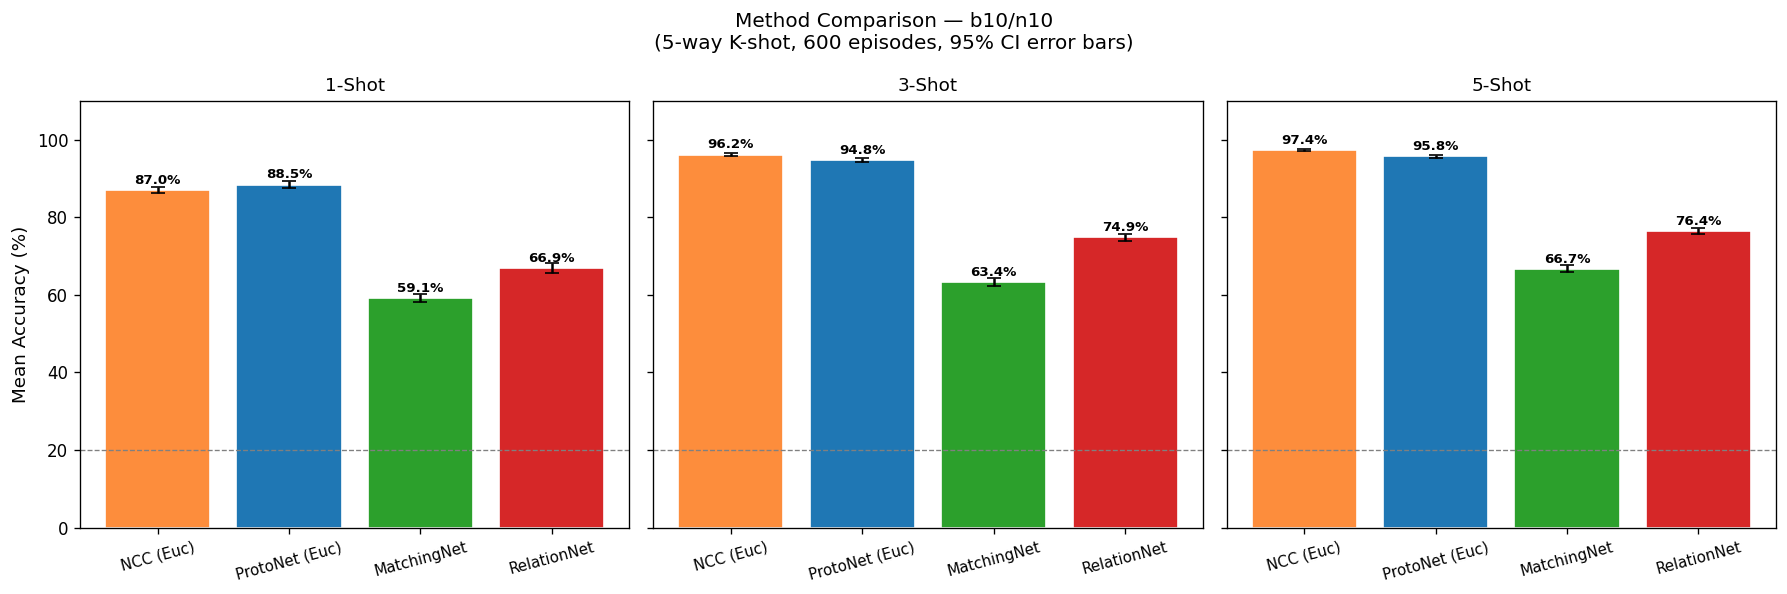

In [8]:
bar_configs = [
    ('NCC (Euc)',      'ncc_{s}shot_euc_json',   '#fd8d3c', '1s'),
    ('ProtoNet (Euc)', 'proto_{s}shot_euc_json',  '#1f77b4', '1s'),
    ('MatchingNet',    'match_{s}shot_json',       '#2ca02c', '1s'),
    ('RelationNet',    'rel_{s}shot_json',         '#d62728', '1s'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, shot in zip(axes, SHOTS):
    labels, vals, errs, colors = [], [], [], []
    for label, key_tmpl, color, _ in bar_configs:
        key = key_tmpl.format(s=shot)
        if R[key] is not None:
            labels.append(label)
            vals.append(float(R[key]['mean_accuracy_pct']))
            errs.append(float(R[key]['ci95_pct']))
            colors.append(color)
    x = np.arange(len(labels))
    bars = ax.bar(x, vals, color=colors, edgecolor='white')
    ax.errorbar(x, vals, yerr=errs, fmt='none', color='black', capsize=4)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.8, f'{v:.1f}%',
                ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9, rotation=15)
    ax.set_title(f'{shot}-Shot', fontsize=11)
    ax.set_ylim(0, 110)
    ax.axhline(y=20, color='gray', linestyle='--', linewidth=0.8)
    if ax == axes[0]:
        ax.set_ylabel('Mean Accuracy (%)', fontsize=11)

fig.suptitle('Method Comparison — b10/n10\n(5-way K-shot, 600 episodes, 95% CI error bars)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/b10n10_accuracy_bar.png', dpi=150)
plt.show()

---
## 8. Per-Class Accuracy Heatmap (b10/n10)


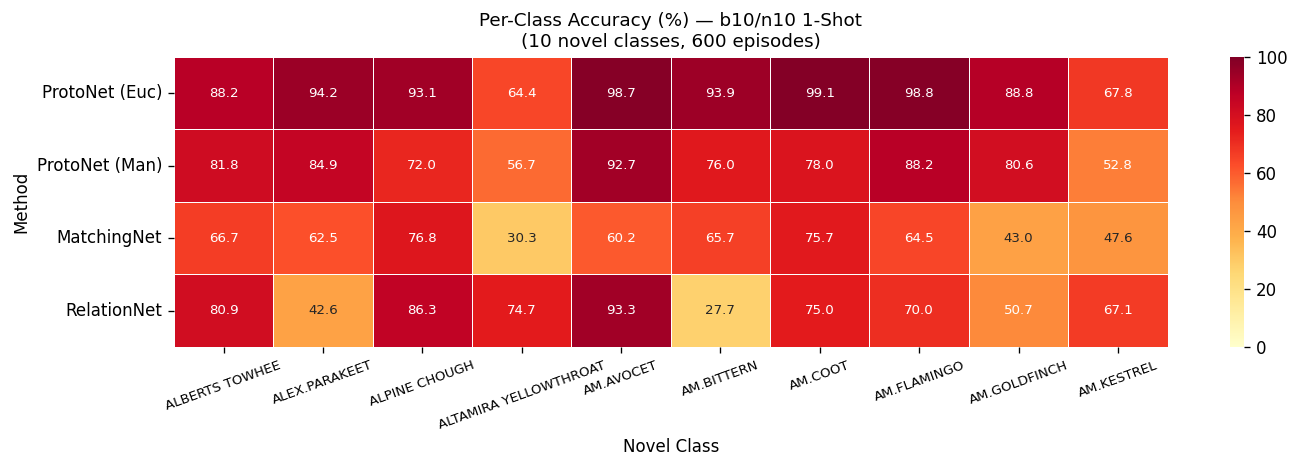

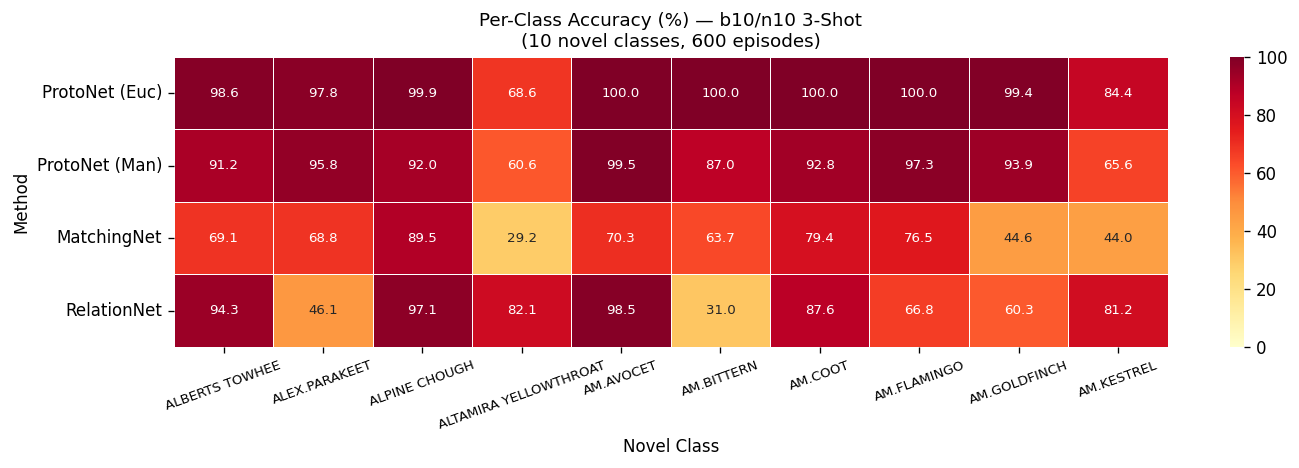

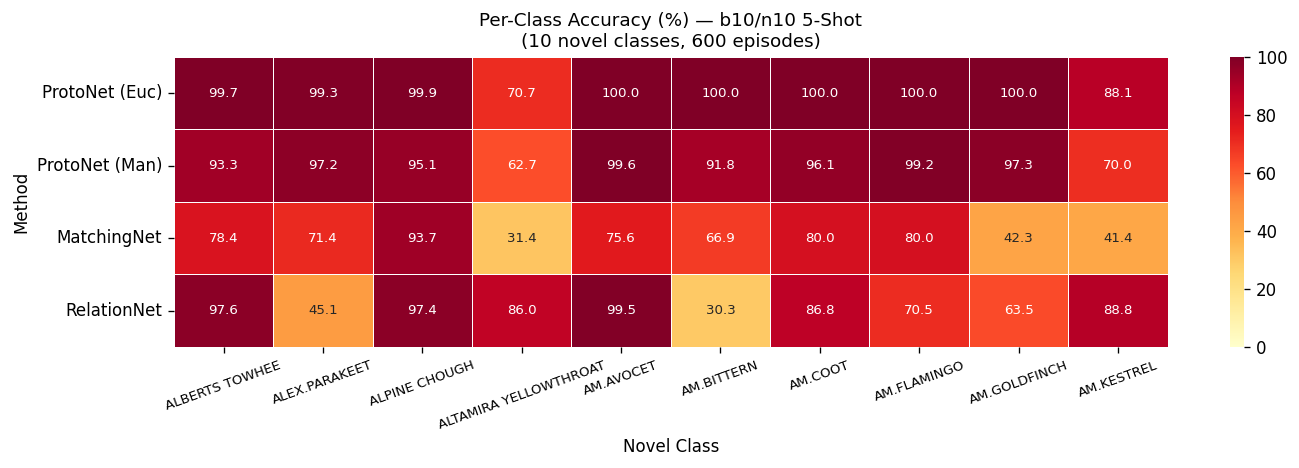

In [9]:
SHORT = [c.replace('AMERICAN ', 'AM.').replace('ALEXANDRINE ', 'ALEX.').replace('ABYSSINIAN ', 'ABYSS.') for c in NOVEL_CLASSES]

for shot in SHOTS:
    method_defs = [
        ('ProtoNet (Euc)',  R[f'proto_{shot}shot_euc_json']),
        ('ProtoNet (Man)',  R[f'proto_{shot}shot_man_json']),
        ('MatchingNet',     R[f'match_{shot}shot_json']),
        ('RelationNet',     R[f'rel_{shot}shot_json']),
    ]

    matrix = []
    row_labels = []
    any_data = False
    for method_name, d in method_defs:
        if d and 'per_class_accuracy_pct' in d:
            pca = d['per_class_accuracy_pct']
            matrix.append([pca.get(c, float('nan')) for c in NOVEL_CLASSES])
            any_data = True
        else:
            matrix.append([float('nan')] * len(NOVEL_CLASSES))
        row_labels.append(method_name)

    if not any_data:
        print(f'{shot}-shot: no data')
        continue

    matrix = np.array(matrix, dtype=float)
    fig, ax = plt.subplots(figsize=(12, 4))
    sns.heatmap(matrix, annot=True, fmt='.1f', cmap='YlOrRd',
                xticklabels=SHORT, yticklabels=row_labels,
                ax=ax, vmin=0, vmax=100,
                linewidths=0.5, linecolor='white',
                annot_kws={'size': 8},
                mask=np.isnan(matrix))
    ax.set_xlabel('Novel Class', fontsize=10)
    ax.set_ylabel('Method', fontsize=10)
    ax.set_title(f'Per-Class Accuracy (%) — b10/n10 {shot}-Shot\n(10 novel classes, 600 episodes)', fontsize=11)
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
    ax.tick_params(axis='y', labelrotation=0)
    plt.tight_layout()
    plt.savefig(f'{ANALYSIS}/b10n10_per_class_heatmap_{shot}shot.png', dpi=150)
    plt.show()

---
## 9. Summary Table


In [10]:
rows = []
for shot in SHOTS:
    for label, key_tmpl in [
        ('NCC (Euclidean)',      'ncc_{s}shot_euc_json'),
        ('NCC (Manhattan)',      'ncc_{s}shot_man_json'),
        ('ProtoNet (Euclidean)', 'proto_{s}shot_euc_json'),
        ('ProtoNet (Manhattan)', 'proto_{s}shot_man_json'),
        ('MatchingNet (Cosine)', 'match_{s}shot_json'),
        ('RelationNet (Learned)','rel_{s}shot_json'),
    ]:
        key = key_tmpl.format(s=shot)
        d = R[key]
        rows.append({
            'Method': label,
            'K-Shot': shot,
            'Accuracy (%)': f"{float(d['mean_accuracy_pct']):.2f}" if d else '—',
            '95% CI':       f"±{float(d['ci95_pct']):.2f}"          if d else '—',
            'Macro F1':     f"{float(d['macro_f1']):.4f}"            if d and d.get('macro_f1') else '—',
            'Precision':    f"{float(d.get('macro_precision', float('nan'))):.4f}" if d and d.get('macro_precision') is not None else '—',
            'Recall':       f"{float(d.get('macro_recall', float('nan'))):.4f}"    if d and d.get('macro_recall') is not None else '—',
        })

summary_df = pd.DataFrame(rows)
summary_df.index = range(1, len(summary_df) + 1)
summary_df

,Method,K-Shot,Accuracy (%),95% CI,Macro F1
1,NCC (Euclidean),1,87.01,±0.81,0.8703
2,NCC (Manhattan),1,76.28,±0.99,0.7654
3,ProtoNet (Euclidean),1,88.45,±0.80,0.8842
4,ProtoNet (Manhattan),1,76.10,±1.00,0.7626
5,MatchingNet (Cosine),1,59.11,±1.01,0.5920
6,RelationNet (Learned),1,66.94,±1.18,0.6693
7,NCC (Euclidean),3,96.20,±0.41,0.9620
8,NCC (Manhattan),3,90.25,±0.61,0.9030
9,ProtoNet (Euclidean),3,94.83,±0.49,0.9485
10,ProtoNet (Manhattan),3,87.64,±0.73,0.8769
